In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('tic_limpio_2025_excel.csv',sep=';', encoding='utf_8_sig')
df.head()

,DIRECTORIO,SECUENCIA_ENCUESTA,SECUENCIA_P,ORDEN,FEX_C,P1_DEPARTAMENTO,NOMBRE_DEPARTAMENTO,P1_MUNICIPIO,CODIGO_DIVIPOLA,NOMBRE_CIUDAD,...,P1085S1,P1085S2,P1085S3,P1084,P1929,P1910,P1911,P1912,P1082,P804
0,8457172,1,1,1,73.359327,91,Amazonas,405,91405,La Chorrera,...,1,0,0,3,0,5,5,5,1,5
1,8457172,2,1,2,73.359327,91,Amazonas,405,91405,La Chorrera,...,1,0,0,2,0,5,5,5,2,5
2,8457172,3,1,3,73.359327,91,Amazonas,405,91405,La Chorrera,...,0,0,0,5,9,5,5,5,2,5
3,8457172,4,1,4,73.359327,91,Amazonas,405,91405,La Chorrera,...,0,0,0,5,9,5,5,5,2,5
4,8457172,5,1,5,73.359327,91,Amazonas,405,91405,La Chorrera,...,0,0,0,5,9,5,5,5,2,5


GRAFICA 1 HISTOGRAMA SOBRE LOS INGRESOS

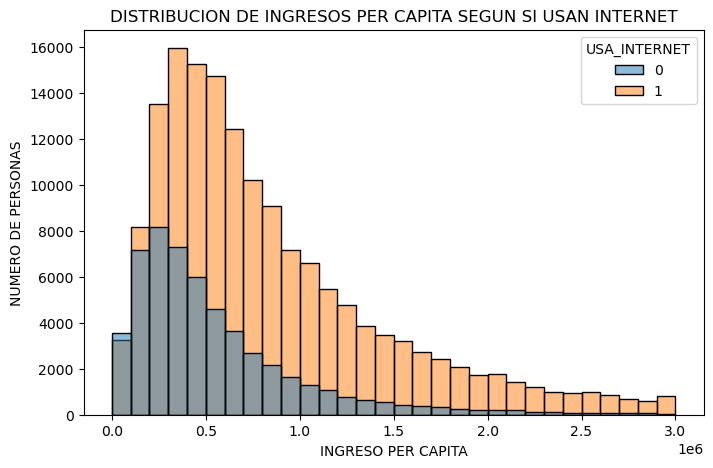

In [2]:
df_ingresos=df[df["PERCAPITA"]<=df["PERCAPITA"].quantile(0.95)]

plt.figure(figsize=(8,5))
sns.histplot(
    data=df_ingresos,
    x='PERCAPITA',
    hue='USA_INTERNET',
    bins=30,
    )
plt.title('DISTRIBUCION DE INGRESOS PER CAPITA SEGUN SI USAN INTERNET')
plt.xlabel('INGRESO PER CAPITA')
plt.ylabel('NUMERO DE PERSONAS')

plt.show()

GRAFICA 2 DIAGRAMA DE CAJAS SOBRE INGRESO PER CAPITA POR ZONA SEGUN USO DE INTERNET

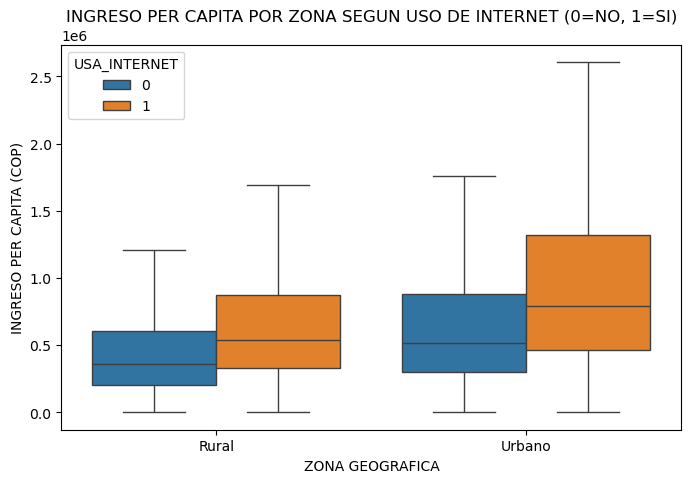

In [3]:
plt.figure(figsize=(8,5))
sns.boxplot(
    data=df_ingresos,
    x='ZONA',
    y='PERCAPITA',
    hue='USA_INTERNET',
    showfliers=False
)
plt.title("INGRESO PER CAPITA POR ZONA SEGUN USO DE INTERNET (0=NO, 1=SI)")
plt.xlabel("ZONA GEOGRAFICA")
plt.ylabel("INGRESO PER CAPITA (COP)")
plt.show()


GRAFICA 3 SOBRE USO DE INTERNET POR NIVEL DE INGRESO Y ZONA (%)

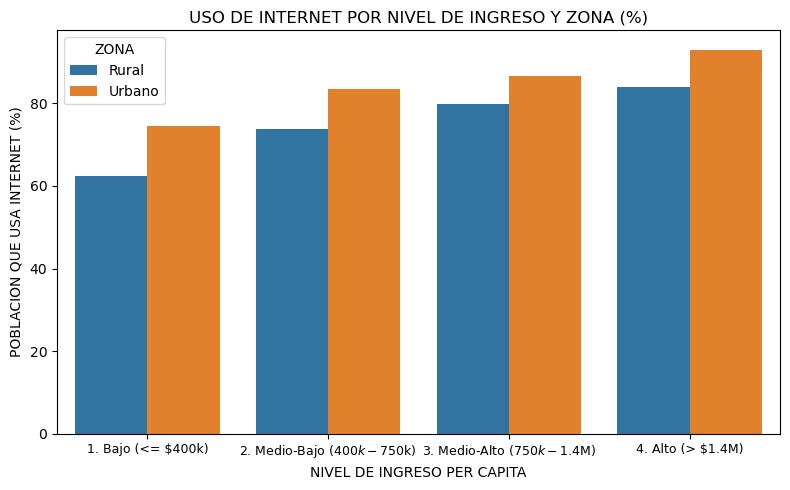

In [4]:
df['FEX_INTERNET']=df['USA_INTERNET']*df['FEX_C']
df_ingreso_por_zona=df.groupby(['NIVEL_INGRESO','ZONA'], as_index=False)[['FEX_C','FEX_INTERNET']].sum()
df_ingreso_por_zona['porcentaje']=(df_ingreso_por_zona['FEX_INTERNET'] / df_ingreso_por_zona['FEX_C'])*100
plt.figure(figsize=(8,5))
sns.barplot(
    data=df_ingreso_por_zona,
    x='NIVEL_INGRESO',
    y='porcentaje',
    hue='ZONA'
)
plt.title('USO DE INTERNET POR NIVEL DE INGRESO Y ZONA (%)')
plt.xlabel('NIVEL DE INGRESO PER CAPITA')
plt.ylabel('POBLACION QUE USA INTERNET (%)')
plt.xticks(fontsize=9)
plt.tight_layout()
plt.show()

GRAFICA 4 SOBRE DEPARTAMENTOS CON MAYOR Y MENOR USO DE INTERNET (%)

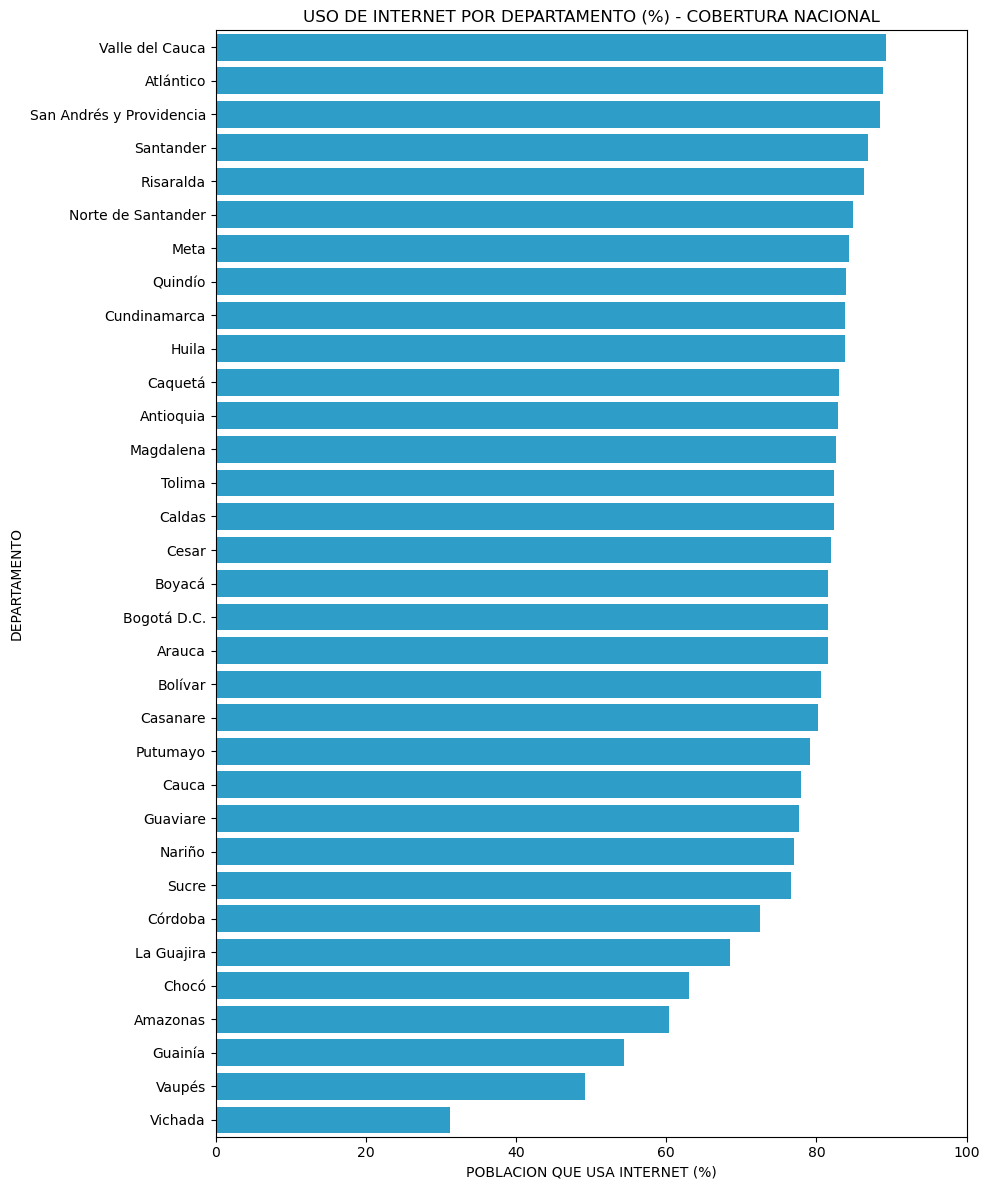

In [13]:
df = pd.read_csv("tic_limpio_2025_excel.csv", sep=";")
df["POND"] = df["USA_INTERNET"] * df["FEX_C"]
uso = df.groupby("NOMBRE_DEPARTAMENTO", as_index=False)[["POND", "FEX_C"]].sum()
uso["PCT"] = (uso["POND"] / uso["FEX_C"]) * 100

plt.figure(figsize=(10, 12))
sns.barplot(data=uso.sort_values("PCT", ascending=False), x="PCT", y="NOMBRE_DEPARTAMENTO", color="#15A9E1")
plt.title("USO DE INTERNET POR DEPARTAMENTO (%) - COBERTURA NACIONAL")
plt.xlabel("POBLACION QUE USA INTERNET (%)")
plt.ylabel("DEPARTAMENTO")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

GRAFICA 5 SOBRE INGRESO PROMEDIO VS USO DE INTERNET POR DEPARTAMENTO

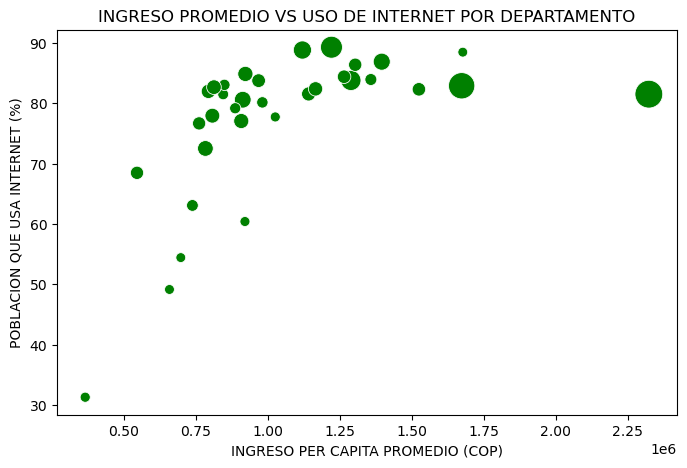

In [8]:
df['FEX_ING']=df['PERCAPITA']*df['FEX_C']
df_DPTOS_AGRUPADOS=df.groupby(['NOMBRE_DEPARTAMENTO'], as_index=False)[['FEX_C', 'FEX_INTERNET', 'FEX_ING']].sum()
df_DPTOS_AGRUPADOS['porcentaje'] = (df_DPTOS_AGRUPADOS['FEX_INTERNET'] / df_DPTOS_AGRUPADOS['FEX_C']) * 100
df_DPTOS_AGRUPADOS['ingreso_prom'] = df_DPTOS_AGRUPADOS['FEX_ING'] / df_DPTOS_AGRUPADOS['FEX_C']
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_DPTOS_AGRUPADOS,
    x='ingreso_prom',
    y='porcentaje',
    size='FEX_C',
    sizes=(50, 400),
    legend=False,
    color='green'
)
plt.title('INGRESO PROMEDIO VS USO DE INTERNET POR DEPARTAMENTO')
plt.xlabel('INGRESO PER CAPITA PROMEDIO (COP)')
plt.ylabel('POBLACION QUE USA INTERNET (%)')
plt.show()

GRAFICA 6 SOBRE MATRIZ DE CORRELACION DE VARIABLES TIC E INGRESO

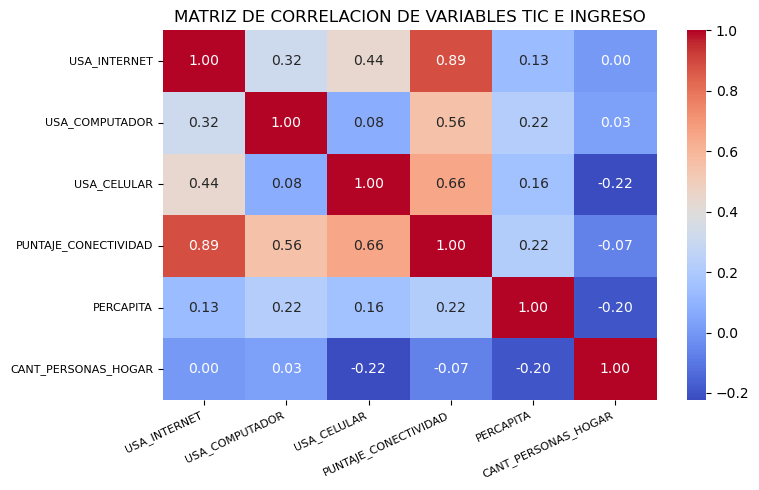

In [9]:
cols = ['USA_INTERNET', 'USA_COMPUTADOR', 'USA_CELULAR', 'PUNTAJE_CONECTIVIDAD', 'PERCAPITA', 'CANT_PERSONAS_HOGAR']
corr = df[cols].corr()

plt.figure(figsize=(8, 5))
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)
plt.title('MATRIZ DE CORRELACION DE VARIABLES TIC E INGRESO')
plt.xticks(rotation=25, ha='right', fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()